# Transit Job Accessibility Analysis in the DART Region

**Research question:** How accessible are jobs via DART for transit-dependent
neighborhoods in the Dallas–Fort Worth metroplex?

**Study area:** All DART service counties: Dallas, Collin, Denton, Rockwall, Ellis
**Focus:** Low-income / carless (transit-dependent) households

**Data (all 2023 except GTFS, which is the current DART feed):**
- GTFS — DART transit schedules
- LODES (WAC) — employment by census block
- ACS B19013 — median household income by tract
- ACS B08201 — vehicle availability by tract
- TIGER/Line — census tract boundaries

In [5]:
# imports
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as cx
from shapely.ops import polygonize, unary_union

# r5py for transit routing / isochrones (requires Java 21)
from r5py import TransportNetwork, Isochrones, TransportMode
import datetime

print("All packages imported successfully.")

All packages imported successfully.


## 1. load census tracts and filter to the DART service area

We load the Texas census-tract shapefile and keep only the five DART counties:
Dallas (113), Collin (085), Denton (121), Rockwall (397), and Ellis (139)

In [6]:
# 1. load census tracts + filter to dart counties
tracts = gpd.read_file("shapefiles/tl_2025_48_tract.shp")
tracts["GEOID"] = tracts["GEOID"].astype(str)   # keep GEOID as text for joining

# DART service-area counties (by county FIPS code)
dart_counties = ["113", "085", "121", "397", "139"]  # Dallas, Collin, Denton, Rockwall, Ellis
dart = tracts[tracts["COUNTYFP"].isin(dart_counties)].copy()

print(f"Census tracts in DART region: {len(dart)}")

Census tracts in DART region: 1123


## 2. Load and clean median household income (ACS B19013, 2023)

The raw ACS file has an extra header row and stores the tract ID in a long format
(e.g. `1400000US48113000100`), so we extract the real GEOID and convert income to a number.

In [ ]:
# 2. load + clean income data (ACS B19013)
# skiprows=[1] drops the ACS descriptive second header row
income = pd.read_csv("census/income_2023.csv", skiprows=[1])

# the GEOID looks like "1400000US48113000100" - the real GEOID is after "US"
income["GEOID"] = income["GEO_ID"].str.split("US").str[1]

# keep only what we need and give the income column a clear name
income = income[["GEOID", "B19013_001E"]].rename(columns={"B19013_001E": "median_income"})

# convert income to numeric ("-" or blank cells become NaN)
income["median_income"] = pd.to_numeric(income["median_income"], errors="coerce")

# join income onto the DART tracts
dart = dart.merge(income, on="GEOID", how="left")

print(f"Tracts with income data: {dart['median_income'].notna().sum()} / {len(dart)}")

Tracts with income data: 1101 / 1123


## 3. Load employment data (LODES WAC, 2023)

LODES reports jobs at the census-block level. Since the first 11 digits of a
15-digit block code are the tract GEOID, we roll block-level jobs up to the tract
level, then join onto the DART tracts.

In [8]:
# 3. load employment data (LODES WAC) + roll up to tracts
# pandas reads the compressed .gz file directly
lodes = pd.read_csv("lodes/tx_wac_S000_JT00_2023.csv.gz")

# Block code is 15 digits; the first 11 are the tract GEOID
lodes["GEOID"] = lodes["w_geocode"].astype(str).str.zfill(15).str[:11]

# Sum all block-level jobs (C000 = total jobs) within each tract
jobs_by_tract = (
    lodes.groupby("GEOID")["C000"].sum().reset_index()
    .rename(columns={"C000": "total_jobs"})
)

# Join jobs onto the DART tracts
dart = dart.merge(jobs_by_tract, on="GEOID", how="left")

print(f"Total jobs across DART region: {dart['total_jobs'].sum():,.0f}")

Total jobs across DART region: 2,905,949


## 4. Map income and jobs (with basemaps)

We reproject to Web Mercator (EPSG:3857) so the Contextily basemap tiles align,
then plot income and jobs as choropleth maps over a real map of the metroplex.

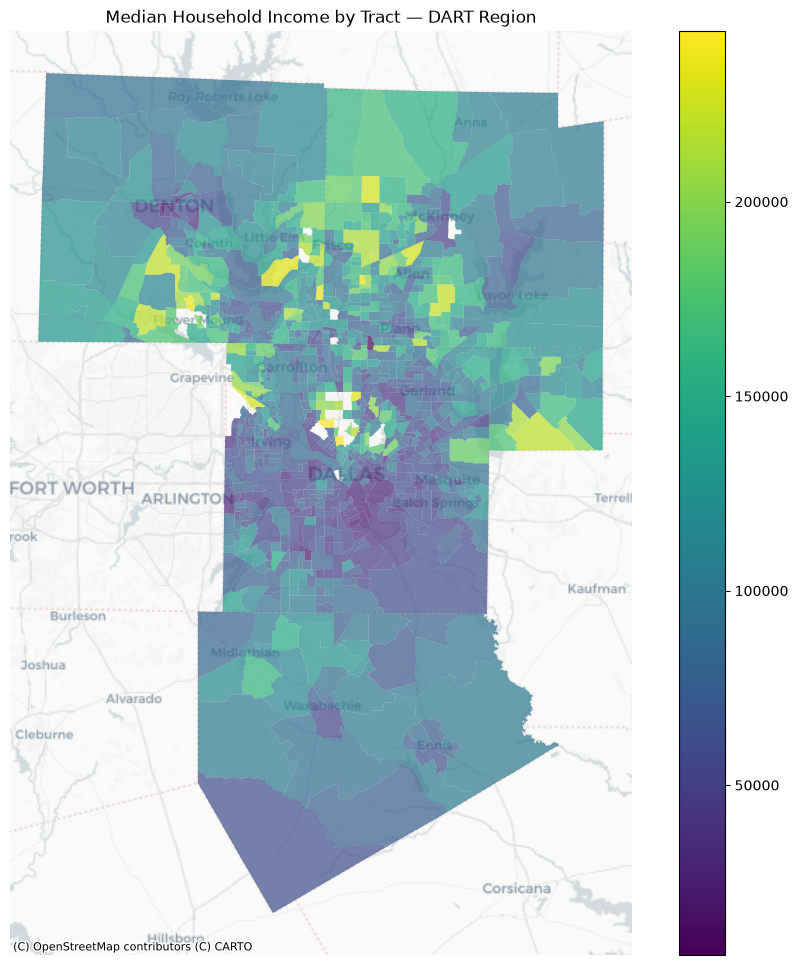

In [9]:
# 4a. income map (with basemap)
# reproject to web mercator so basemap tiles line up
dart_web = dart.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(12, 12))
dart_web.plot(column="median_income", ax=ax, legend=True, alpha=0.7, cmap="viridis")
cx.add_basemap(ax, source=cx.providers.CartoDB.Positron)
ax.set_title("Median Household Income by Tract — DART Region")
ax.set_axis_off()
plt.show()

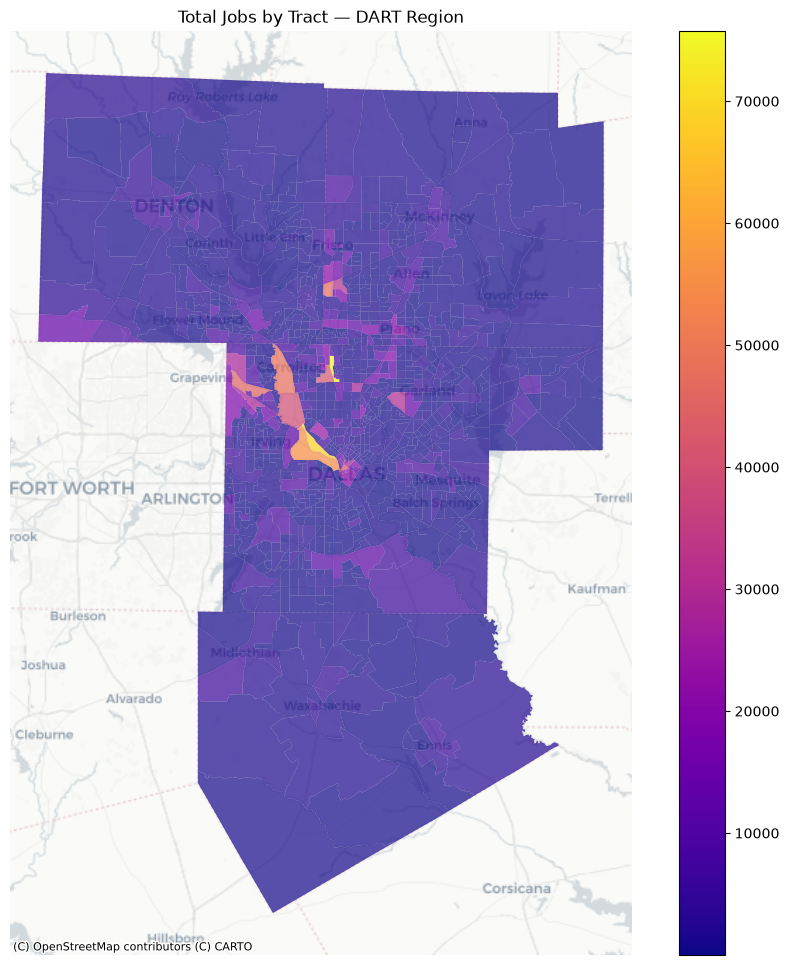

In [10]:

# 4b. jobs map (with basemap)
fig, ax = plt.subplots(figsize=(12, 12))
dart_web.plot(column="total_jobs", ax=ax, legend=True, alpha=0.7, cmap="plasma")
cx.add_basemap(ax, source=cx.providers.CartoDB.Positron)
ax.set_title("Total Jobs by Tract — DART Region")
ax.set_axis_off()
plt.show()

## 5. Build the transport network (r5py)

We build a combined street + transit network from the DFW OpenStreetMap extract
and the DART GTFS feed. This is what r5py uses to compute travel times.

*Note: the OSM file was cropped to the DFW area because the full Texas extract
exceeds r5py's size limit. `allow_errors=True` skips a non-critical GTFS fare
formatting issue that doesn't affect travel-time routing.*

In [11]:
# 5. build transport network (streets + transit)
# osm/dfw.osm.pbf = DFW-cropped street network
# gtfs/google_transit.zip = DART transit schedules
print("Building transport network (this can take a few minutes)...")
network = TransportNetwork(
    "osm/dfw.osm.pbf",
    ["gtfs/google_transit.zip"],
    allow_errors=True   # skip non-critical GTFS fare validation issues
)
print("Network built!")

Building transport network (this can take a few minutes)...
Network built!


/Users/sanjulajuttada/Downloads/transit_research/.venv/lib/python3.14/site-packages/r5py/r5/transport_network.py:266: RuntimeWarning: R5 reported the following issues with GTFS file google_transit.zip: 
RangeError: fare_attributes line 26: Number 2678400.0 outside of acceptable range [0.0,86400.0].
- RangeError: fare_attributes line 7: Number 2678400.0 outside of acceptable range [0.0,86400.0].
- RangeError: fare_attributes line 19: Number 2678400.0 outside of acceptable range [0.0,86400.0].
- RangeError: fare_attributes line 11: Number 2678400.0 outside of acceptable range [0.0,86400.0].
- RangeError: fare_attributes line 15: Number 2678400.0 outside of acceptable range [0.0,86400.0].
- RangeError: fare_attributes line 23: Number 2678400.0 outside of acceptable range [0.0,86400.0].
- RangeError: fare_attributes line 4: Number 2678400.0 outside of acceptable range [0.0,86400.0].
  warnings.warn(


## 6. Compute tract centroids

For each tract we need a single origin point. We reproject to EPSG:3083
(a Texas-centric projection in meters) for accurate centroids, then convert
those centroids back to lat/lon (EPSG:4326) for use with r5py.

In [12]:

# 6. tract centroids (origins for isochrones)
# EPSG:3083 is in meters -> accurate centroids (EPSG:4326 degrees would distort)
dart_projected = dart.to_crs("epsg:3083")
dart_projected["centroid"] = dart_projected.geometry.centroid

# build a GeoDataFrame of centroids, projected back to lat/lon for r5py
centroids = dart_projected[["GEOID"]].copy()
centroids = gpd.GeoDataFrame(
    centroids,
    geometry=dart_projected["centroid"],
    crs="epsg:3083"
).to_crs("epsg:4326")

print(f"Centroids ready: {len(centroids)} tracts")
print(centroids.head(3))

Centroids ready: 1123 tracts
         GEOID                    geometry
0  48113017819  POINT (-96.63241 32.81649)
1  48113005400  POINT (-96.81744 32.72731)
2  48113005500  POINT (-96.79954 32.72518)


## 7. Compute transit isochrones from each tract

For each tract centroid, we compute the area reachable within 45 minutes by
transit + walking (departing 8:30 AM on a weekday). Job counts inside each
isochrone give a "jobs reachable by transit" measure per tract.

sample test down below

In [14]:

# 7. isochrone loop (sample shown; full run -> HPC)
# set to `centroids` for the full run (slow); a small sample here for demonstration
origins_to_run = centroids.head(5)

results = []
for idx, row in origins_to_run.iterrows():
    origin = gpd.GeoDataFrame(
        {"id": [row["GEOID"]]},
        geometry=[row.geometry],
        crs="EPSG:4326"
    )
    iso = Isochrones(
        network,
        origins=origin,
        departure=datetime.datetime(2026, 6, 12, 8, 30),   # weekday, morning peak
        isochrones=[datetime.timedelta(minutes=45)],
        transport_modes=[TransportMode.TRANSIT, TransportMode.WALK],
    )
    iso["GEOID"] = row["GEOID"]      # tag each isochrone with its origin tract
    results.append(iso)

# combine into one GeoDataFrame
all_isochrones = gpd.GeoDataFrame(pd.concat(results, ignore_index=True), crs="EPSG:4326")

# convert the travel_time duration to plain minutes (GeoPackage can't store timedelta)
all_isochrones["minutes"] = all_isochrones["travel_time"].dt.total_seconds() / 60
all_isochrones = all_isochrones.drop(columns=["travel_time"])

# save so the (slow) results can be reloaded without recomputing
all_isochrones.to_file("sample_isochrones.gpkg", driver="GPKG")

## 8. Count jobs reachable by transit

r5py returns isochrones as boundary lines, so we first fill them into polygons.
Then we place each tract's jobs at its centroid and use a spatial join to count
how many jobs fall inside each isochrone — i.e. jobs reachable within 45 minutes.

In [15]:

# 8. count jobs reachable by transit
# r5py returns MultiLineString rings; fill them into solid polygons
# (a point can't fall "inside" a line, only a polygon)
filled = []
for idx, row in all_isochrones.iterrows():
    polys = list(polygonize(row.geometry))
    filled.append(unary_union(polys) if polys else None)

iso_filled = all_isochrones.copy()
iso_filled["geometry"] = filled
iso_filled = gpd.GeoDataFrame(iso_filled[iso_filled.geometry.notna()], crs="EPSG:4326")

# job points = tract centroids carrying that tract's job count
job_points = centroids.merge(dart[["GEOID", "total_jobs"]], on="GEOID", how="left")

# spatial join: which job points fall inside each isochrone?
reachable = gpd.sjoin(job_points, iso_filled, how="inner", predicate="within")

# Ssum jobs reachable from each origin tract
jobs_reachable = (
    reachable.groupby("GEOID_right")["total_jobs"].sum().reset_index()
    .rename(columns={"GEOID_right": "GEOID", "total_jobs": "jobs_reachable_45min"})
)

print(jobs_reachable)

         GEOID  jobs_reachable_45min
0  48113005300                 74245
1  48113005400                117006
2  48113005500                 29917
3  48113005600                 65850
4  48113017819                 13674


## 9. Combine accessibility with income

We merge the "jobs reachable" measure back onto the tract data (which has income)
so we can compare transit job access against income

In [16]:

# 9. combine accesibility with income
# merge jobs-reachable back onto the tract data (which already has income)
result = dart.merge(jobs_reachable, on="GEOID", how="left")

# preview tracts that have an accessibility result
summary = result[["GEOID", "median_income", "total_jobs", "jobs_reachable_45min"]]
print(summary.dropna(subset=["jobs_reachable_45min"]))

# on the full dataset, this correlation is the comparison
valid = result.dropna(subset=["median_income", "jobs_reachable_45min"])
if len(valid) > 2:
    corr = valid["median_income"].corr(valid["jobs_reachable_45min"])
    print(f"\nIncome vs. jobs reachable — correlation: {corr:.3f} (n={len(valid)})")

         GEOID  median_income  total_jobs  jobs_reachable_45min
0  48113017819        41326.0        2010               13674.0
1  48113005400        47047.0         556              117006.0
2  48113005500        64893.0         193               29917.0
3  48113005300        68424.0         189               74245.0
4  48113005600        58058.0         188               65850.0

Income vs. jobs reachable — correlation: 0.049 (n=5)
